In [1]:
from pathlib import Path
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 220)

PROCESSED = Path("processed")
MODEL_DIR = Path("models")

MODEL_DIR.mkdir(exist_ok=True)

DATA_PATH = (
    PROCESSED /
    "burninwatch_modeling_dataset_final.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (687, 40)


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,supplyVoltage_mean,supplyVoltage_std,node2Voltage_mean,node2Voltage_std,node2Voltage_iqr,node2Voltage_slope,collectorEmitterCurrent_mean,collectorEmitterCurrent_std,collectorEmitterCurrent_q05,collectorEmitterCurrent_q95,collectorEmitterCurrent_iqr,collectorEmitterCurrent_slope,packageTemperature_mean,packageTemperature_std,packageTemperature_q05,packageTemperature_q95,packageTemperature_iqr,packageTemperature_slope,supply_node1_mean_diff,node1_node2_mean_diff,estimated_power_proxy,node2Voltage_delta_from_baseline,node2Voltage_pct_change_from_baseline,collectorEmitterCurrent_delta_from_baseline,collectorEmitterCurrent_pct_change_from_baseline,packageTemperature_delta_from_baseline,packageTemperature_pct_change_from_baseline,current_residual,current_residual_abs,package_temperature_residual,current_per_node2V,node_voltage_drop
0,0,Device_2,Device2 1.mat,main,0,100,0.000,22.671,2.454372,0.006901,1.952854,0.103817,0.139707,0.005401,0.118606,0.056871,0.080834,0.174992,0.072177,0.000347,44.674700,10.876925,30.402502,62.593386,19.625527,1.644183,0.003014,0.498504,0.231621,-0.073491,-0.036268,0.000000,0.000000,-33.393921,-0.427751,0.001394,0.001394,-51.722321,0.060735,0.498504
1,1,Device_2,Device2 1.mat,main,1,100,22.911,45.542,2.454399,0.006417,2.026345,0.088584,0.156998,0.001211,0.119897,0.048703,0.083021,0.164384,0.063428,-0.000851,78.068621,6.957067,66.747572,88.169319,11.951787,1.054713,0.002392,0.425662,0.242952,0.000000,0.000000,0.001290,0.010880,0.000000,0.000000,0.006630,0.006630,-18.328890,0.059169,0.425662
2,2,Device_2,Device2 1.mat,main,2,100,45.776,68.042,2.456576,0.005668,2.117639,0.192635,0.195728,0.016992,0.107692,0.039220,0.085099,0.157494,0.056867,-0.001148,96.348991,3.567825,90.350834,100.860965,6.200524,0.542141,0.002275,0.336661,0.228053,0.091294,0.045053,-0.010914,-0.092019,18.280369,0.234158,-0.000786,0.000786,-0.086894,0.050855,0.336661
3,3,Device_2,Device2 1.mat,main,3,100,68.282,90.812,2.457120,0.005396,2.097679,0.151077,0.127604,-0.009018,0.110033,0.038414,0.085208,0.159682,0.056867,0.001033,97.329904,1.702277,95.143693,100.038545,3.043599,0.046638,0.002626,0.356815,0.230813,0.071334,0.035203,-0.008574,-0.072287,19.261282,0.246722,0.000454,0.000454,0.884389,0.052454,0.356815
4,4,Device_2,Device2 1.mat,main,4,100,91.050,113.501,2.457609,0.005506,2.171392,0.208924,0.456469,-0.023517,0.097325,0.032439,0.083021,0.157385,0.006562,0.000371,97.966307,1.998920,95.579187,101.089235,3.909730,-0.214554,0.001595,0.284622,0.211331,0.145046,0.071580,-0.021281,-0.179428,19.897686,0.254874,-0.008321,0.008321,1.512138,0.044822,0.284622


In [2]:
# ============================================================
# FEATURE DEFINITIONS
# ============================================================

META = [
    "sample_id",
    "device_id",
    "file_name",
    "file_role",
    "window_index",
    "window_size",
    "window_start_seconds",
    "window_end_seconds",
]

ALL_FEATURES = [
    c for c in df.columns
    if c not in META
]

STRESS_AWARE_FEATURES = [
    # Electrical response / stability
    "node2Voltage_std",
    "node2Voltage_iqr",
    "node2Voltage_slope",

    "collectorEmitterCurrent_mean",
    "collectorEmitterCurrent_std",
    "collectorEmitterCurrent_q05",
    "collectorEmitterCurrent_q95",
    "collectorEmitterCurrent_iqr",
    "collectorEmitterCurrent_slope",

    # Thermal variation
    "packageTemperature_std",
    "packageTemperature_iqr",

    # Change from early baseline
    "collectorEmitterCurrent_delta_from_baseline",
    "collectorEmitterCurrent_pct_change_from_baseline",

    # Context-aware response
    "current_residual",
    "current_residual_abs",

    # Relationships
    "current_per_node2V",
    "node_voltage_drop",
]

COMPACT_FEATURES = [
    "collectorEmitterCurrent_mean",
    "collectorEmitterCurrent_std",
    "collectorEmitterCurrent_iqr",
    "collectorEmitterCurrent_slope",

    "collectorEmitterCurrent_delta_from_baseline",
    "collectorEmitterCurrent_pct_change_from_baseline",

    "current_residual",
    "current_residual_abs",

    "current_per_node2V",
    "node_voltage_drop",

    "node2Voltage_std",
    "node2Voltage_iqr",

    "packageTemperature_std",
    "packageTemperature_iqr",
]

FEATURE_SETS = {
    "all_32": ALL_FEATURES,
    "stress_aware": STRESS_AWARE_FEATURES,
    "compact_response": COMPACT_FEATURES,
}

for name, features in FEATURE_SETS.items():

    missing = [
        c for c in features
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{name} has missing columns: {missing}"
        )

    print(
        f"{name:20s}: "
        f"{len(features)} features"
    )

assert len(ALL_FEATURES) == 32

all_32              : 32 features
stress_aware        : 17 features
compact_response    : 14 features


In [3]:
# ============================================================
# TEMPORAL BASELINE SPLIT
# ============================================================

work = df.copy()

work = work.sort_values(
    [
        "device_id",
        "file_name",
        "window_index"
    ]
).reset_index(drop=True)

work["split"] = "excluded"

for (device_id, file_name), group in work.groupby(
    ["device_id", "file_name"],
    sort=False
):

    group = group.sort_values(
        "window_index"
    )

    indices = group.index.to_numpy()

    role = group["file_role"].iloc[0]
    n = len(group)

    # Check files are completely excluded from fitting.
    if role == "check":

        work.loc[
            indices,
            "split"
        ] = "check_holdout"

        continue

    # Protect against tiny experiments.
    if n < 10:

        work.loc[
            indices,
            "split"
        ] = "short_file_holdout"

        continue

    n_train = max(
        3,
        int(np.floor(n * 0.20))
    )

    n_val = max(
        1,
        int(np.floor(n * 0.20))
    )

    # Earliest windows
    work.loc[
        indices[:n_train],
        "split"
    ] = "baseline_train"

    # Next section
    work.loc[
        indices[n_train:n_train + n_val],
        "split"
    ] = "validation"

    # Remaining windows
    work.loc[
        indices[n_train + n_val:],
        "split"
    ] = "evaluation"


print("Overall split:")
display(
    work["split"]
    .value_counts()
    .to_frame("windows")
)

print("\nSplit by device:")
display(
    work.groupby(
        ["device_id", "split"]
    )
    .size()
    .unstack(fill_value=0)
)

Overall split:


,windows
split,
evaluation,415
baseline_train,134
validation,134
check_holdout,4



Split by device:


split,baseline_train,check_holdout,evaluation,validation
device_id,,,,
Device_2,34,1,106,34
Device_3,29,1,92,29
Device_4,50,0,154,50
Device_5,21,2,63,21


In [4]:
# ============================================================
# SPLIT VALIDATION
# ============================================================

split_audit_rows = []

for (device_id, file_name), group in work.groupby(
    ["device_id", "file_name"]
):

    row = {
        "device_id": device_id,
        "file_name": file_name,
        "file_role": group["file_role"].iloc[0],
    }

    for split_name in [
        "baseline_train",
        "validation",
        "evaluation",
        "check_holdout",
    ]:

        part = group[
            group["split"] == split_name
        ]

        row[
            f"{split_name}_count"
        ] = len(part)

        if len(part):

            row[
                f"{split_name}_first_window"
            ] = int(
                part["window_index"].min()
            )

            row[
                f"{split_name}_last_window"
            ] = int(
                part["window_index"].max()
            )

    split_audit_rows.append(row)


split_audit = pd.DataFrame(
    split_audit_rows
)

display(split_audit)

# Verify chronological ordering.
for _, row in split_audit.iterrows():

    if (
        row["baseline_train_count"] > 0
        and row["validation_count"] > 0
    ):
        assert (
            row["baseline_train_last_window"]
            <
            row["validation_first_window"]
        )

    if (
        row["validation_count"] > 0
        and row["evaluation_count"] > 0
    ):
        assert (
            row["validation_last_window"]
            <
            row["evaluation_first_window"]
        )

print("✅ Temporal split verified.")

,device_id,file_name,file_role,baseline_train_count,baseline_train_first_window,baseline_train_last_window,validation_count,validation_first_window,validation_last_window,evaluation_count,evaluation_first_window,evaluation_last_window,check_holdout_count,check_holdout_first_window,check_holdout_last_window
0,Device_2,Device2 1.mat,main,22,0.0,21.0,22,22.0,43.0,66,44.0,109.0,0,NaN,NaN
1,Device_2,Device2b 1.mat,b,12,0.0,11.0,12,12.0,23.0,40,24.0,63.0,0,NaN,NaN
2,Device_2,Device2check 1.mat,check,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,1,0.0,0.0
3,Device_3,Device3 1.mat,main,19,0.0,18.0,19,19.0,37.0,60,38.0,97.0,0,NaN,NaN
4,Device_3,Device3b 1.mat,b,10,0.0,9.0,10,10.0,19.0,32,20.0,51.0,0,NaN,NaN
5,Device_3,Device3check 1.mat,check,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,1,0.0,0.0
6,Device_4,Device4 1.mat,main,21,0.0,20.0,21,21.0,41.0,66,42.0,107.0,0,NaN,NaN
7,Device_4,Device4b 1.mat,b,29,0.0,28.0,29,29.0,57.0,88,58.0,145.0,0,NaN,NaN
8,Device_5,Device5 1.mat,main,21,0.0,20.0,21,21.0,41.0,63,42.0,104.0,0,NaN,NaN
9,Device_5,Device5check 1.mat,check,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,2,0.0,1.0


✅ Temporal split verified.


In [5]:
# ============================================================
# ISOLATION FOREST MODEL
# ============================================================

def make_isolation_forest(
    random_state=42
):

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            RobustScaler()
        ),

        (
            "model",
            IsolationForest(
                n_estimators=500,

                contamination="auto",

                max_samples="auto",

                random_state=random_state,

                n_jobs=-1
            )
        )
    ])


def get_anomaly_score(
    model,
    X
):

    # sklearn:
    # higher decision_function = more normal
    #
    # We reverse the sign:
    # higher score = more anomalous

    return -model.decision_function(X)

In [6]:
# ============================================================
# TRAIN ALL EXPERIMENTS
# ============================================================

models = {}
thresholds = {}
training_summary = []

train_mask = (
    work["split"]
    == "baseline_train"
)

val_mask = (
    work["split"]
    == "validation"
)

eval_mask = (
    work["split"]
    == "evaluation"
)

check_mask = (
    work["split"]
    == "check_holdout"
)


for experiment_name, feature_list in FEATURE_SETS.items():

    print(
        "\n" + "=" * 70
    )

    print(
        f"TRAINING: {experiment_name}"
    )

    print(
        "=" * 70
    )

    model = make_isolation_forest()

    X_train = work.loc[
        train_mask,
        feature_list
    ]

    X_val = work.loc[
        val_mask,
        feature_list
    ]

    X_eval = work.loc[
        eval_mask,
        feature_list
    ]

    X_check = work.loc[
        check_mask,
        feature_list
    ]

    # ONLY baseline training data enters fit()
    model.fit(X_train)

    score_col = (
        f"{experiment_name}_anomaly_score"
    )

    flag_col = (
        f"{experiment_name}_anomaly_flag"
    )

    work[score_col] = np.nan

    # Validation score
    if len(X_val):

        work.loc[
            val_mask,
            score_col
        ] = get_anomaly_score(
            model,
            X_val
        )

    # Evaluation score
    if len(X_eval):

        work.loc[
            eval_mask,
            score_col
        ] = get_anomaly_score(
            model,
            X_eval
        )

    # Check-file score
    if len(X_check):

        work.loc[
            check_mask,
            score_col
        ] = get_anomaly_score(
            model,
            X_check
        )

    # Calibrate threshold from validation only.
    validation_scores = (
        work.loc[
            val_mask,
            score_col
        ]
        .dropna()
    )

    threshold = float(
        validation_scores.quantile(0.95)
    )

    thresholds[
        experiment_name
    ] = threshold

    work[flag_col] = (
        work[score_col]
        > threshold
    ).astype("Int64")

    models[
        experiment_name
    ] = model

    model_path = (
        MODEL_DIR /
        f"burninwatch_{experiment_name}_isolation_forest.joblib"
    )

    joblib.dump(
        model,
        model_path
    )

    training_summary.append({

        "experiment":
            experiment_name,

        "feature_count":
            len(feature_list),

        "train_windows":
            len(X_train),

        "validation_windows":
            len(X_val),

        "evaluation_windows":
            len(X_eval),

        "check_windows":
            len(X_check),

        "validation_95pct_threshold":
            threshold,

        "model_path":
            str(model_path)
    })


training_summary = pd.DataFrame(
    training_summary
)

display(
    training_summary
)

print(
    "\n✅ All three Isolation Forest models trained."
)


TRAINING: all_32

TRAINING: stress_aware

TRAINING: compact_response


,experiment,feature_count,train_windows,validation_windows,evaluation_windows,check_windows,validation_95pct_threshold,model_path
0,all_32,32,134,134,415,4,0.102613,models\burninwatch_all_32_isolation_forest.joblib
1,stress_aware,17,134,134,415,4,0.043463,models\burninwatch_stress_aware_isolation_fore...
2,compact_response,14,134,134,415,4,0.052215,models\burninwatch_compact_response_isolation_...



✅ All three Isolation Forest models trained.


In [7]:
# ============================================================
# SCORE DISTRIBUTIONS
# ============================================================

summary_rows = []

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_anomaly_score"
    )

    for split_name in [
        "baseline_train",
        "validation",
        "evaluation",
        "check_holdout",
    ]:

        scores = (
            work.loc[
                work["split"] == split_name,
                score_col
            ]
            .dropna()
        )

        if len(scores) == 0:
            continue

        summary_rows.append({

            "experiment":
                experiment_name,

            "split":
                split_name,

            "count":
                len(scores),

            "mean":
                scores.mean(),

            "median":
                scores.median(),

            "std":
                scores.std(),

            "q90":
                scores.quantile(0.90),

            "q95":
                scores.quantile(0.95),

            "q99":
                scores.quantile(0.99),

            "max":
                scores.max()
        })


score_summary = pd.DataFrame(
    summary_rows
)

display(
    score_summary
)

,experiment,split,count,mean,median,std,q90,q95,q99,max
0,all_32,validation,134,0.054548,0.069014,0.045057,0.097270,0.102613,0.116368,0.130464
1,all_32,evaluation,415,0.078790,0.080167,0.025412,0.101924,0.114271,0.147850,0.188978
2,all_32,check_holdout,4,0.072321,0.071961,0.019708,0.089676,0.089898,0.090075,0.090119
3,stress_aware,validation,134,-0.021172,-0.023210,0.037542,0.024353,0.043463,0.073667,0.091878
4,stress_aware,evaluation,415,-0.003464,-0.005059,0.045920,0.049191,0.079931,0.144527,0.196099
5,stress_aware,check_holdout,4,0.070017,0.069871,0.037281,0.102454,0.102567,0.102658,0.102681
6,compact_response,validation,134,-0.012904,-0.017635,0.042227,0.041526,0.052215,0.092348,0.124808
7,compact_response,evaluation,415,0.006895,0.009198,0.050633,0.061612,0.098084,0.163095,0.210447
8,compact_response,check_holdout,4,0.087501,0.087613,0.038569,0.120994,0.121064,0.121120,0.121134


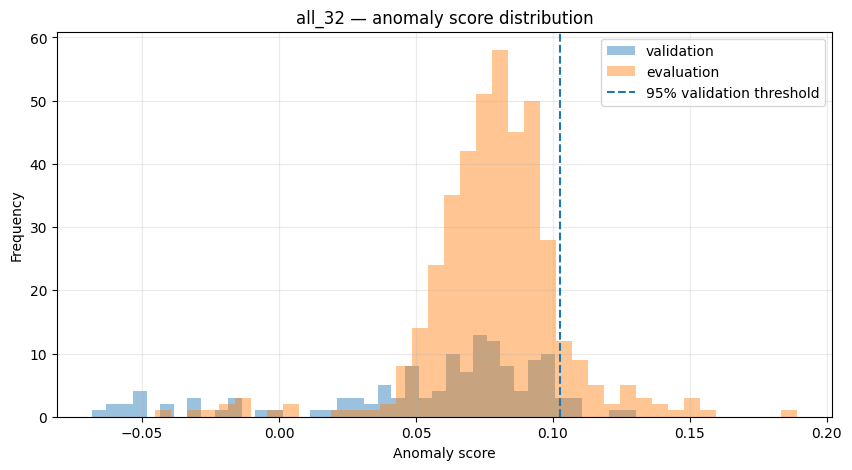

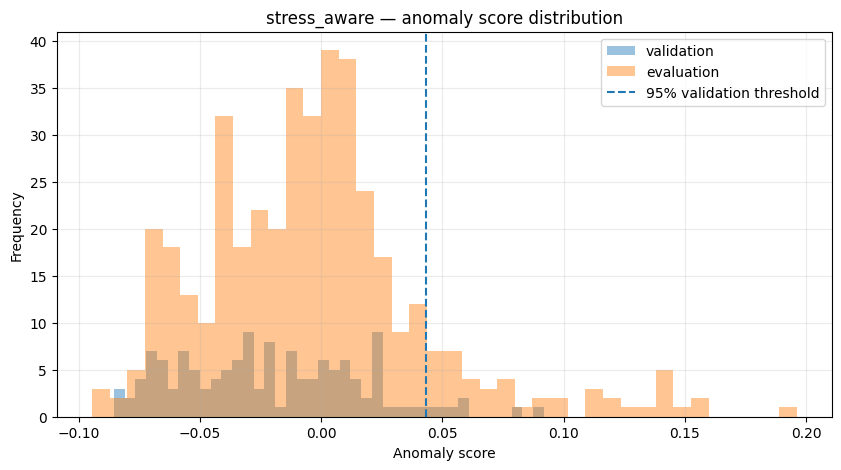

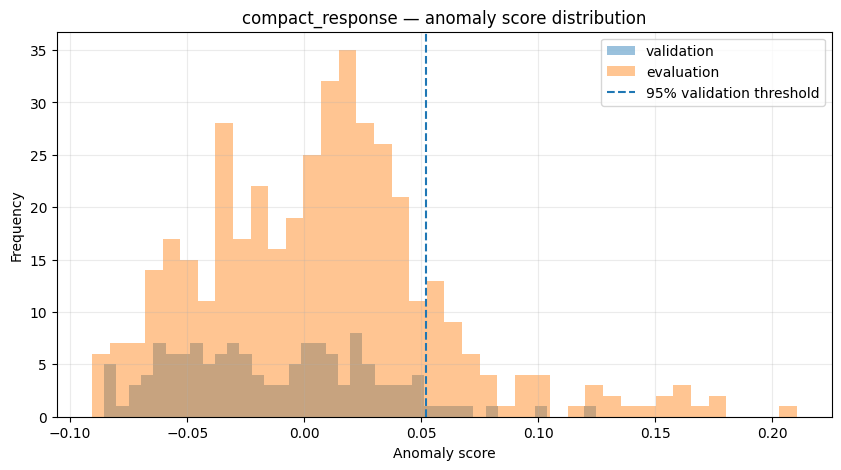

In [8]:
# ============================================================
# HISTOGRAMS
# ============================================================

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_anomaly_score"
    )

    plt.figure(
        figsize=(10, 5)
    )

    for split_name in [
        "baseline_train",
        "validation",
        "evaluation"
    ]:

        scores = (
            work.loc[
                work["split"] == split_name,
                score_col
            ]
            .dropna()
        )

        if len(scores):

            plt.hist(
                scores,
                bins=40,
                alpha=0.45,
                label=split_name
            )

    plt.axvline(
        thresholds[experiment_name],
        linestyle="--",
        label="95% validation threshold"
    )

    plt.title(
        f"{experiment_name} — anomaly score distribution"
    )

    plt.xlabel(
        "Anomaly score"
    )

    plt.ylabel(
        "Frequency"
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    plt.show()

In [9]:
# ============================================================
# FLAG SUMMARY
# ============================================================

flag_rows = []

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_anomaly_score"
    )

    flag_col = (
        f"{experiment_name}_anomaly_flag"
    )

    threshold = thresholds[
        experiment_name
    ]

    for split_name in [
        "baseline_train",
        "validation",
        "evaluation",
        "check_holdout"
    ]:

        part = work[
            work["split"] == split_name
        ]

        scores = (
            part[score_col]
            .dropna()
        )

        if not len(scores):
            continue

        flags = (
            scores
            > threshold
        )

        flag_rows.append({

            "experiment":
                experiment_name,

            "split":
                split_name,

            "windows":
                len(scores),

            "flagged":
                int(flags.sum()),

            "flag_fraction":
                flags.mean()
        })


flag_summary = pd.DataFrame(
    flag_rows
)

display(
    flag_summary
)

,experiment,split,windows,flagged,flag_fraction
0,all_32,validation,134,7,0.052239
1,all_32,evaluation,415,41,0.098795
2,all_32,check_holdout,4,0,0.000000
3,stress_aware,validation,134,7,0.052239
4,stress_aware,evaluation,415,47,0.113253
5,stress_aware,check_holdout,4,2,0.500000
6,compact_response,validation,134,7,0.052239
7,compact_response,evaluation,415,58,0.139759
8,compact_response,check_holdout,4,4,1.000000


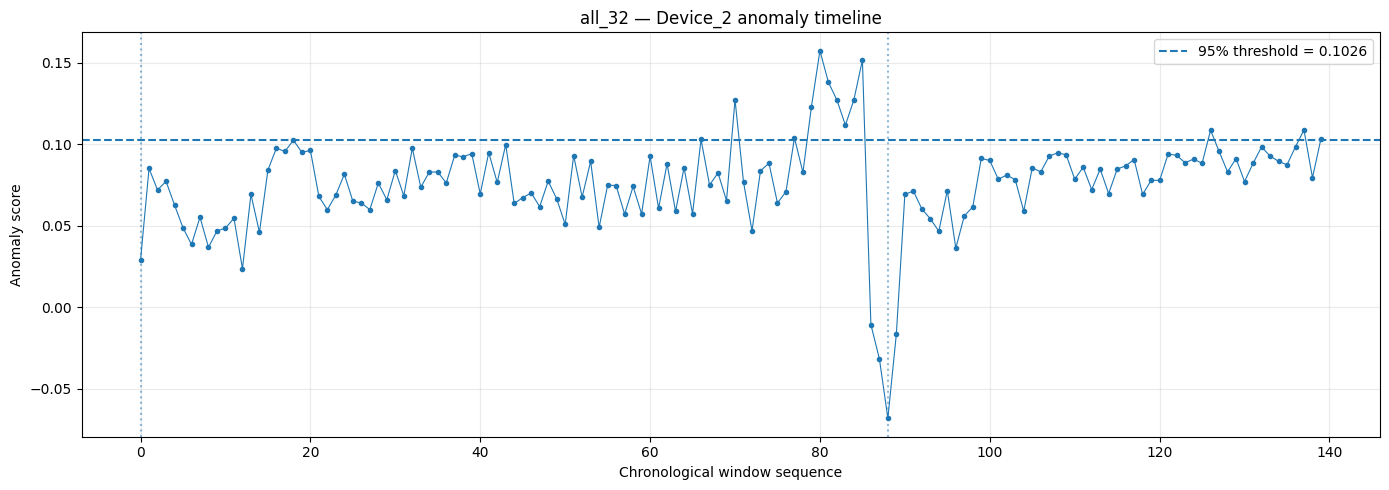

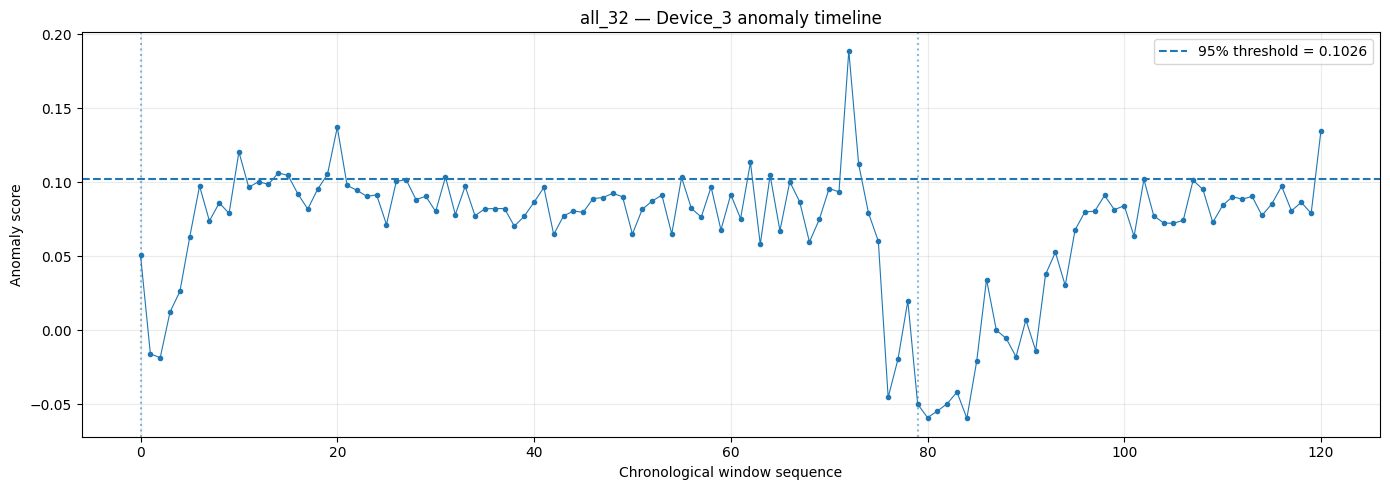

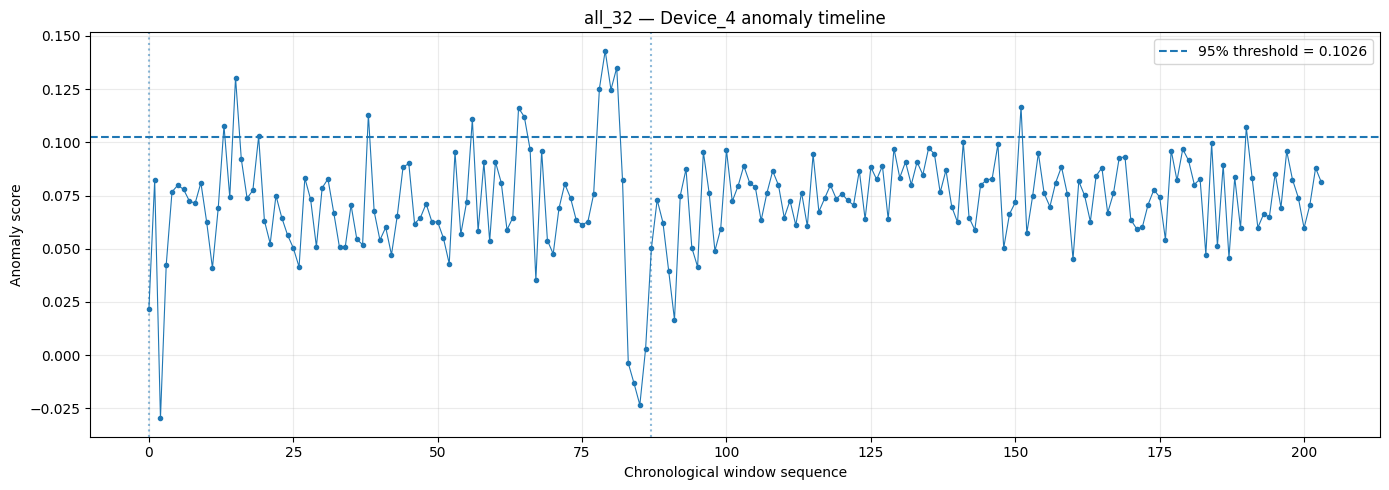

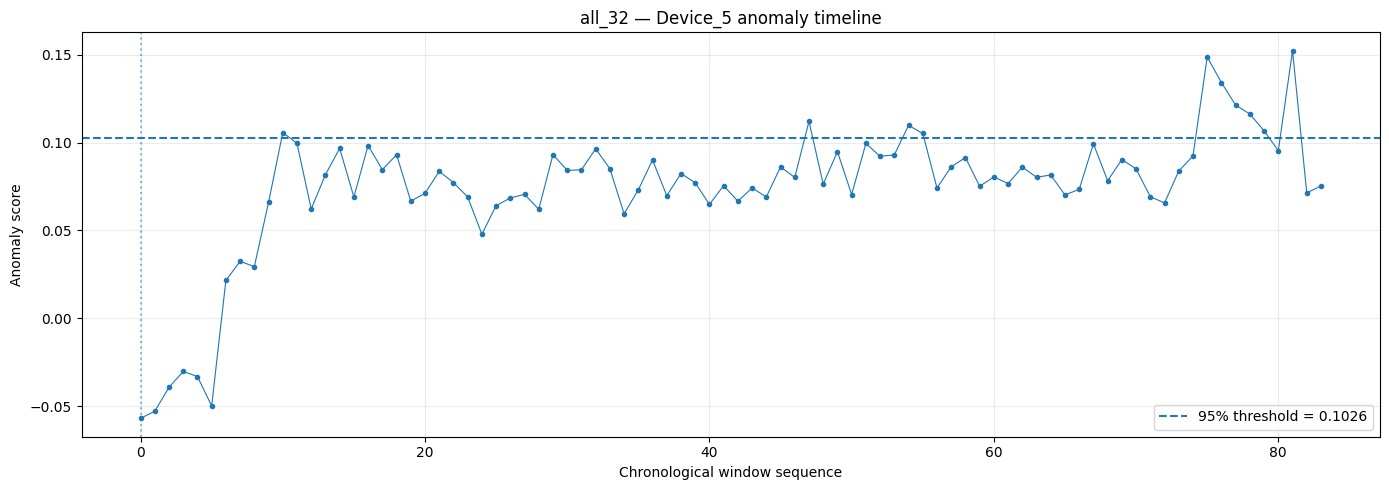

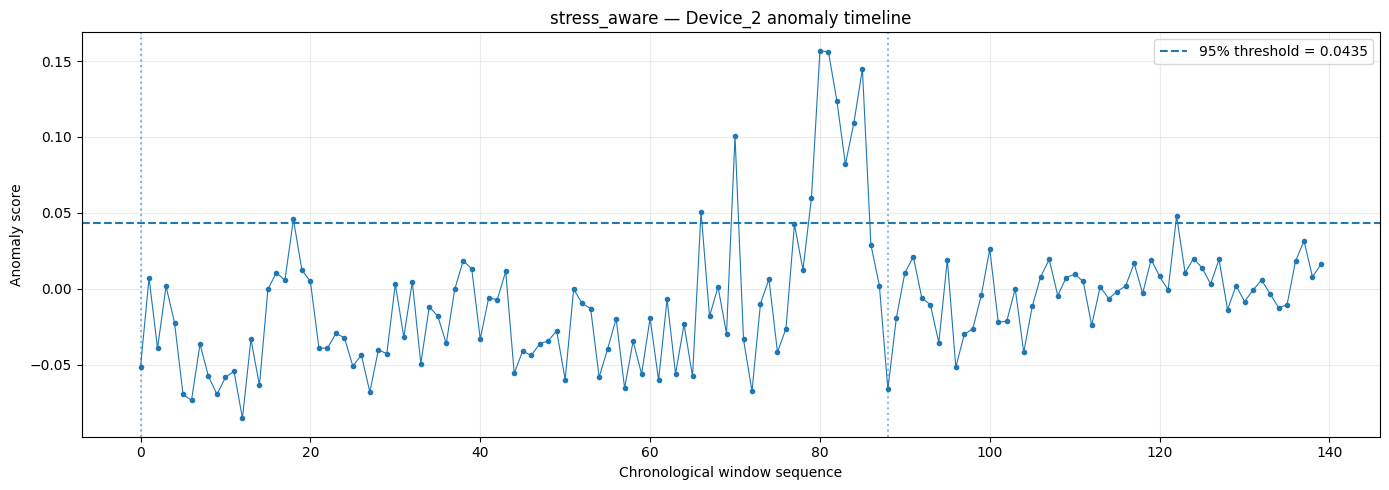

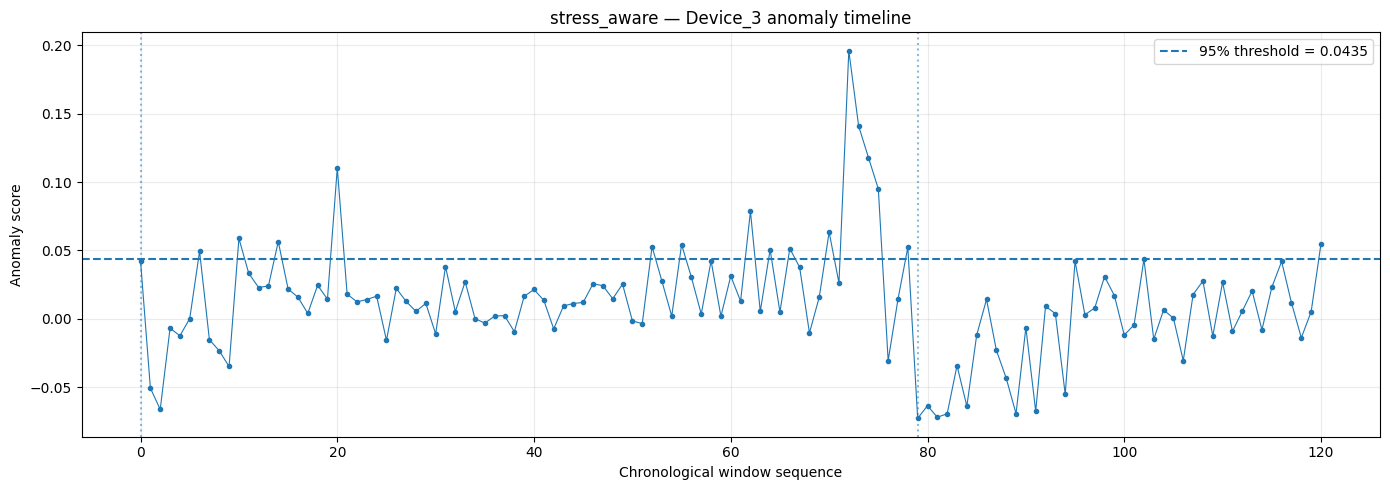

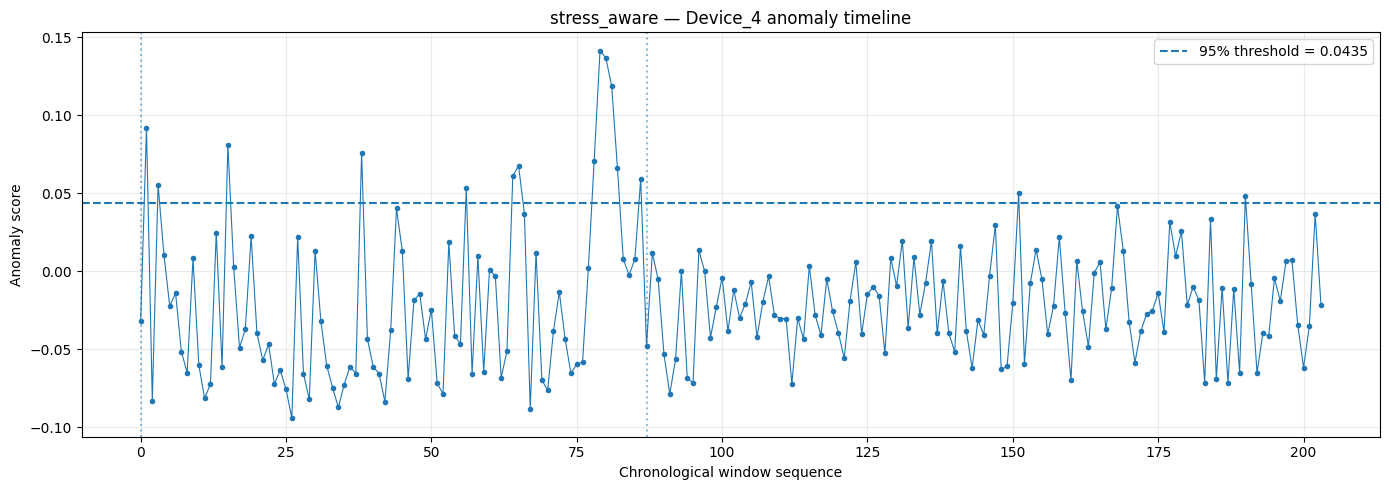

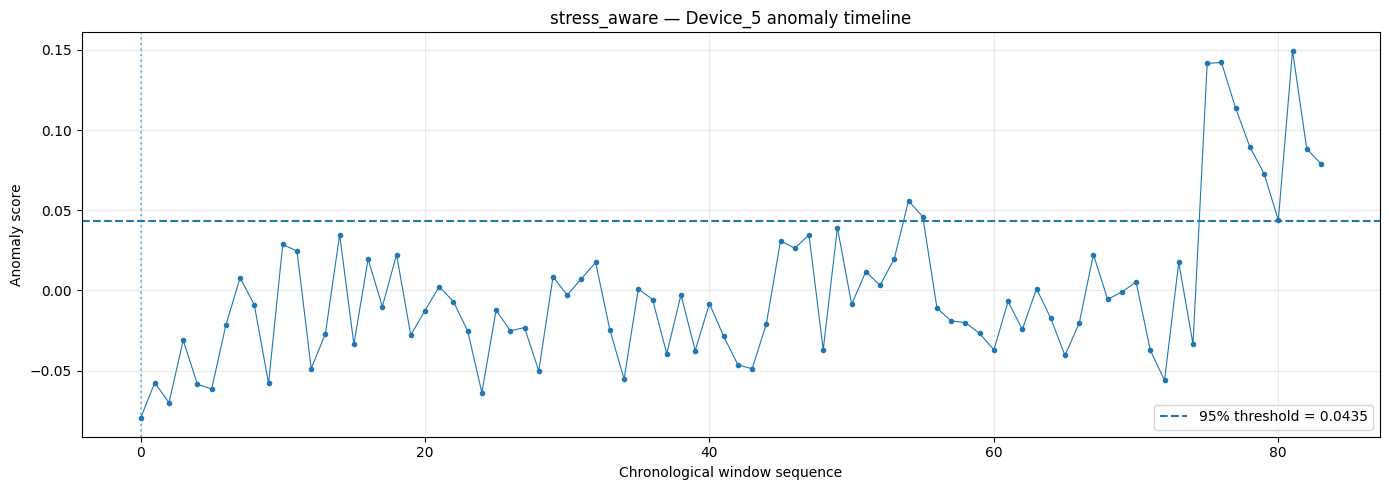

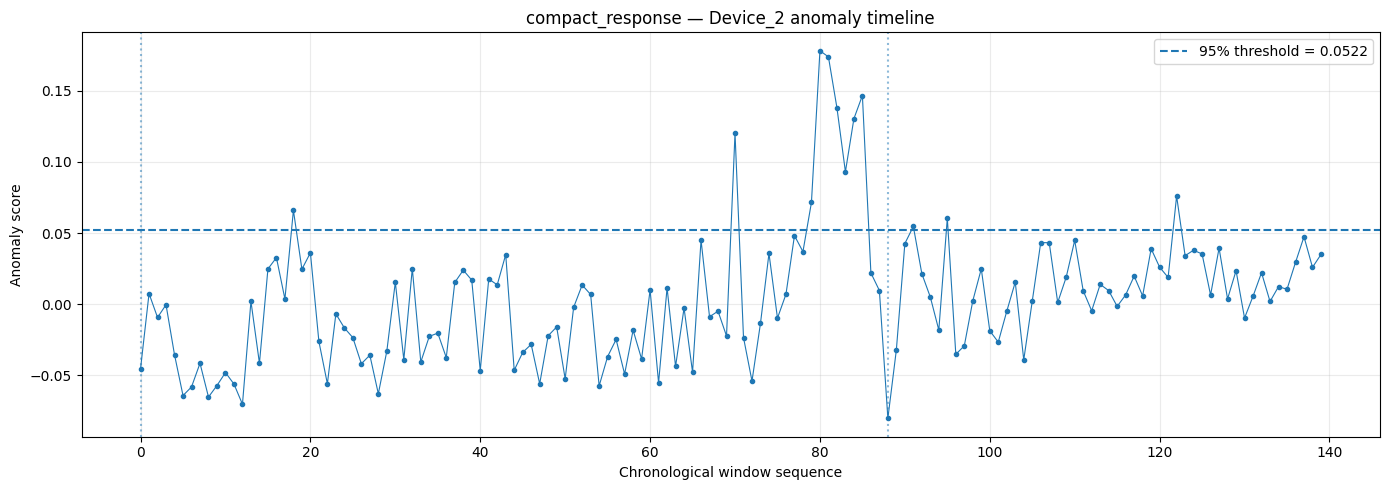

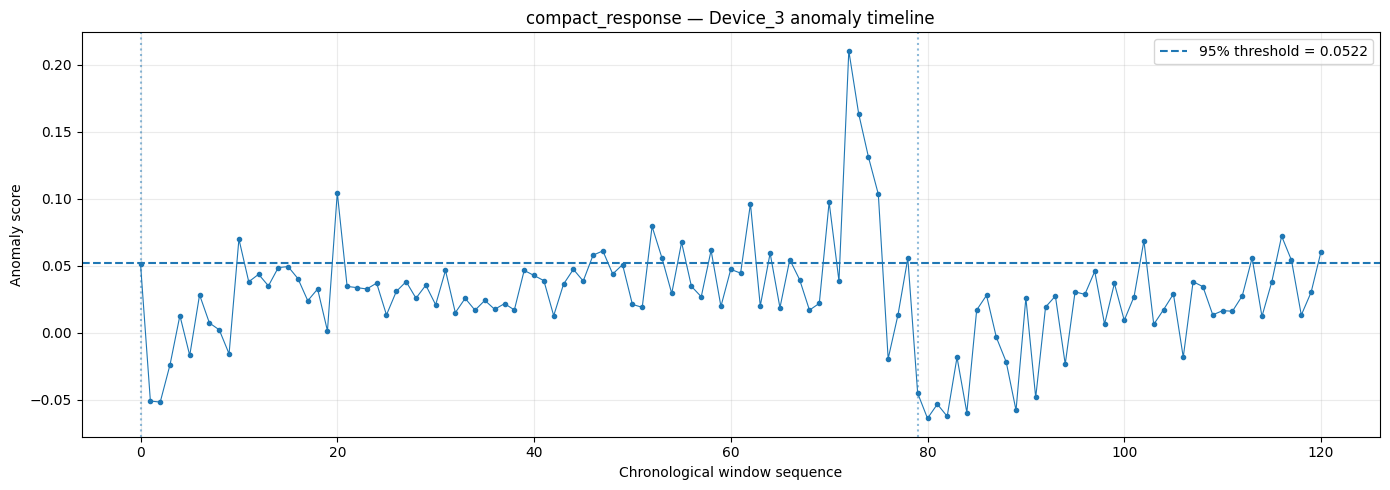

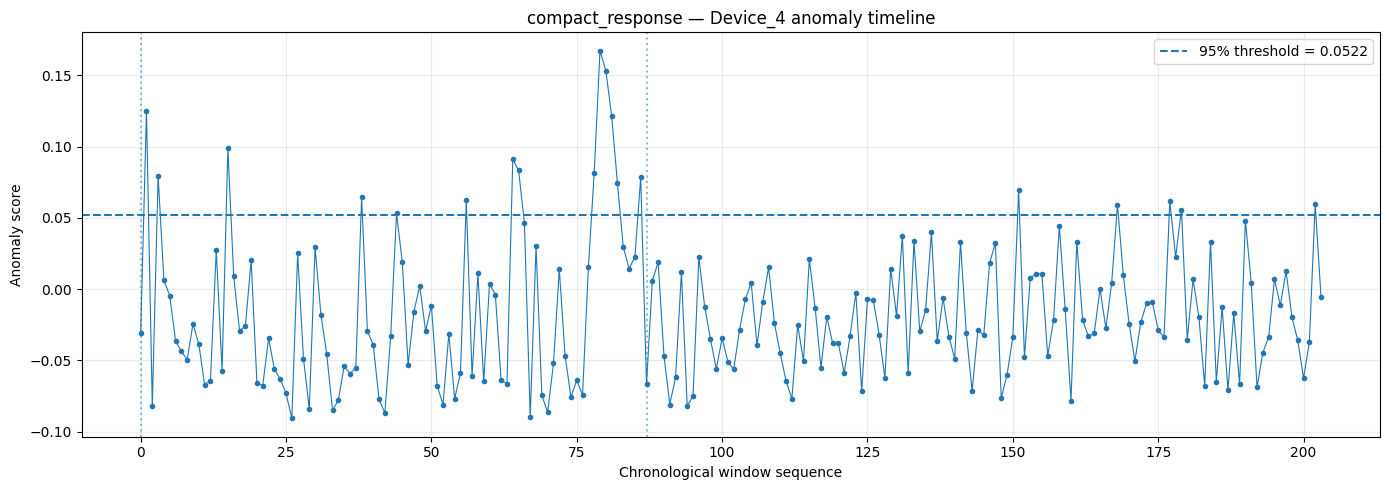

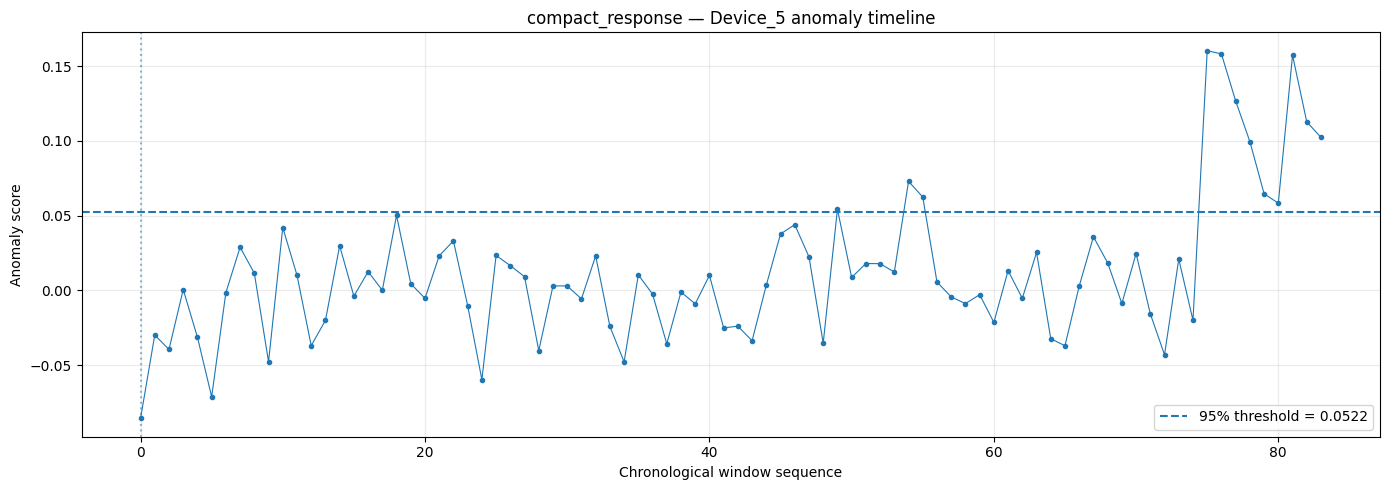

In [10]:
# ============================================================
# ANOMALY SCORE TIMELINES
# ============================================================

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_anomaly_score"
    )

    threshold = thresholds[
        experiment_name
    ]

    for device_id, group in work.groupby(
        "device_id"
    ):

        group = group[
            group["split"].isin([
                "validation",
                "evaluation"
            ])
        ].copy()

        if len(group) == 0:
            continue

        group = group.sort_values(
            [
                "file_name",
                "window_index"
            ]
        ).reset_index(
            drop=True
        )

        x = np.arange(
            len(group)
        )

        plt.figure(
            figsize=(14, 5)
        )

        plt.plot(
            x,
            group[score_col],
            marker=".",
            linewidth=0.8
        )

        plt.axhline(
            threshold,
            linestyle="--",
            label=(
                f"95% threshold = "
                f"{threshold:.4f}"
            )
        )

        # Mark source-file boundaries.
        previous_file = None

        for xpos, file_name in enumerate(
            group["file_name"]
        ):

            if file_name != previous_file:

                plt.axvline(
                    xpos,
                    linestyle=":",
                    alpha=0.5
                )

                previous_file = file_name

        plt.title(
            f"{experiment_name} — "
            f"{device_id} anomaly timeline"
        )

        plt.xlabel(
            "Chronological window sequence"
        )

        plt.ylabel(
            "Anomaly score"
        )

        plt.legend()

        plt.grid(
            alpha=0.25
        )

        plt.tight_layout()

        plt.show()

In [11]:
# ============================================================
# TOP ANOMALOUS WINDOWS
# ============================================================

TOP_N = 20

for experiment_name in FEATURE_SETS:

    score_col = (
        f"{experiment_name}_anomaly_score"
    )

    flag_col = (
        f"{experiment_name}_anomaly_flag"
    )

    top = (
        work[
            work["split"] == "evaluation"
        ]
        .sort_values(
            score_col,
            ascending=False
        )
        [
            META +
            [
                score_col,
                flag_col
            ]
        ]
        .head(TOP_N)
    )

    print(
        "\n" + "=" * 70
    )

    print(
        f"TOP {TOP_N} — "
        f"{experiment_name}"
    )

    print(
        "=" * 70
    )

    display(top)
    


TOP 20 — all_32


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,all_32_anomaly_score,all_32_anomaly_flag
266,266,Device_3,Device3 1.mat,main,91,100,2100.673000,2122.623000,0.188978,1
102,102,Device_2,Device2 1.mat,main,102,100,2327.088000,2349.014000,0.157474,1
682,682,Device_5,Device5 1.mat,main,102,100,2317.276999,2339.330999,0.152244,1
107,107,Device_2,Device2 1.mat,main,107,100,2439.044000,2460.878000,0.151702,1
676,676,Device_5,Device5 1.mat,main,96,100,2184.038000,2206.366000,0.148626,1
426,426,Device_4,Device4 1.mat,main,100,100,2287.451000,2309.755000,0.143082,1
103,103,Device_2,Device2 1.mat,main,103,100,2349.298000,2371.748000,0.138115,1
214,214,Device_3,Device3 1.mat,main,39,100,897.578000,920.240000,0.137251,1
428,428,Device_4,Device4 1.mat,main,102,100,2332.293000,2354.454000,0.135121,1
324,324,Device_3,Device3b 1.mat,b,51,100,1167.434000,1190.110000,0.135006,1



TOP 20 — stress_aware


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,stress_aware_anomaly_score,stress_aware_anomaly_flag
266,266,Device_3,Device3 1.mat,main,91,100,2100.673000,2122.623000,0.196099,1
102,102,Device_2,Device2 1.mat,main,102,100,2327.088000,2349.014000,0.156849,1
103,103,Device_2,Device2 1.mat,main,103,100,2349.298000,2371.748000,0.156069,1
682,682,Device_5,Device5 1.mat,main,102,100,2317.276999,2339.330999,0.149519,1
107,107,Device_2,Device2 1.mat,main,107,100,2439.044000,2460.878000,0.144903,1
677,677,Device_5,Device5 1.mat,main,97,100,2206.602000,2228.313000,0.142222,1
676,676,Device_5,Device5 1.mat,main,96,100,2184.038000,2206.366000,0.141551,1
426,426,Device_4,Device4 1.mat,main,100,100,2287.451000,2309.755000,0.141443,1
267,267,Device_3,Device3 1.mat,main,92,100,2122.887000,2144.965000,0.140972,1
427,427,Device_4,Device4 1.mat,main,101,100,2310.016000,2332.025000,0.136865,1



TOP 20 — compact_response


,sample_id,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,compact_response_anomaly_score,compact_response_anomaly_flag
266,266,Device_3,Device3 1.mat,main,91,100,2100.673000,2122.623000,0.210447,1
102,102,Device_2,Device2 1.mat,main,102,100,2327.088000,2349.014000,0.178122,1
103,103,Device_2,Device2 1.mat,main,103,100,2349.298000,2371.748000,0.173782,1
426,426,Device_4,Device4 1.mat,main,100,100,2287.451000,2309.755000,0.167322,1
267,267,Device_3,Device3 1.mat,main,92,100,2122.887000,2144.965000,0.163551,1
676,676,Device_5,Device5 1.mat,main,96,100,2184.038000,2206.366000,0.160290,1
677,677,Device_5,Device5 1.mat,main,97,100,2206.602000,2228.313000,0.158177,1
682,682,Device_5,Device5 1.mat,main,102,100,2317.276999,2339.330999,0.157290,1
427,427,Device_4,Device4 1.mat,main,101,100,2310.016000,2332.025000,0.153421,1
107,107,Device_2,Device2 1.mat,main,107,100,2439.044000,2460.878000,0.146644,1


In [12]:
# ============================================================
# SAVE RESULTS
# ============================================================

scored_path = (
    PROCESSED /
    "burninwatch_scored_windows_isolation_forest_v1.csv"
)

work.to_csv(
    scored_path,
    index=False
)

score_summary.to_csv(
    PROCESSED /
    "burninwatch_isolation_forest_score_summary_v1.csv",
    index=False
)

flag_summary.to_csv(
    PROCESSED /
    "burninwatch_isolation_forest_flag_summary_v1.csv",
    index=False
)

training_summary.to_csv(
    PROCESSED /
    "burninwatch_isolation_forest_training_summary_v1.csv",
    index=False
)

artifacts = {}

for experiment_name in FEATURE_SETS:

    artifacts[experiment_name] = {

        "features":
            FEATURE_SETS[
                experiment_name
            ],

        "threshold_95_validation":
            thresholds[
                experiment_name
            ],

        "model_path":
            str(
                MODEL_DIR /
                f"burninwatch_{experiment_name}_isolation_forest.joblib"
            )
    }


with open(
    MODEL_DIR /
    "burninwatch_isolation_forest_artifacts_v1.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        artifacts,
        f,
        indent=2
    )


print("Saved:")
print(
    scored_path
)

print(
    PROCESSED /
    "burninwatch_isolation_forest_score_summary_v1.csv"
)

print(
    PROCESSED /
    "burninwatch_isolation_forest_flag_summary_v1.csv"
)

print(
    MODEL_DIR /
    "burninwatch_isolation_forest_artifacts_v1.json"
)

Saved:
processed\burninwatch_scored_windows_isolation_forest_v1.csv
processed\burninwatch_isolation_forest_score_summary_v1.csv
processed\burninwatch_isolation_forest_flag_summary_v1.csv
models\burninwatch_isolation_forest_artifacts_v1.json


In [14]:
# ============================================================
# FINAL CHECK
# ============================================================

assert len(work) == 687

for experiment_name in FEATURE_SETS:

    assert (
        f"{experiment_name}_anomaly_score"
        in work.columns
    )

    assert (
        f"{experiment_name}_anomaly_flag"
        in work.columns
    )

print(
    "\n" + "=" * 70
)

print(
    "✅ BURNINWATCH ISOLATION FOREST BASELINE COMPLETE"
)

print(
    "=" * 70
)

for name, threshold in thresholds.items():

    eval_part = work[
        work["split"] == "evaluation"
    ]

    score_col = (
        f"{name}_anomaly_score"
    )

    flags = (
        eval_part[score_col]
        > threshold
    )

    print(
        f"{name:20s} | "
        f"threshold={threshold:.6f} | "
        f"evaluation flags="
        f"{int(flags.sum())}/"
        f"{len(flags)}"
    )


✅ BURNINWATCH ISOLATION FOREST BASELINE COMPLETE
all_32               | threshold=0.102613 | evaluation flags=41/415
stress_aware         | threshold=0.043463 | evaluation flags=47/415
compact_response     | threshold=0.052215 | evaluation flags=58/415
